# Celestial Mechanics and Star-Chart Predictors: Equations and Derivation

This notebook now follows the textbook sequence explicitly: **Hamilton's principle -> Lagrange equations -> canonical momenta -> Hamilton equations -> interpretation**.


Renderer note: Mermaid blocks depend on notebook renderer support. A Python-rendered fallback diagram cell is included below so the diagram always appears.
## Theory Diagram (from Physical Model to Data Fit)
Mermaid source is kept for portability, but many notebook renderers do not embed Mermaid directly.
Run the Python-rendered fallback cell below to view the guaranteed rendered theory diagram.

## Underlying Physical Properties
- System class: gravitating bodies in orbital motion.
- State choice: position vectors q_i(t) and canonical momenta p_i(t).
- Modeling principle: dynamics are generated by a variational principle, not by curve-fitting alone.
- Symmetry logic: conserved quantities come from explicit symmetries (time, translation, rotation) when the required conditions hold.

## Trivial Case Before Full Model
We first solve the simplest consistent limit: **two-body Kepler reduction in one effective radial coordinate**.
This is used to verify signs, units, and conservation structure before introducing richer interactions or damping.

## Lagrangian Derivation (Line-by-Line)
1. Choose one effective coordinate $q(t)$ in the trivial limit.
2. Write kinetic term: $T=\frac{1}{2}m\dot q^2$.
3. Write local quadratic potential near equilibrium: $V=\frac{1}{2}kq^2$.
4. Define Lagrangian: $L=T-V=\frac{1}{2}m\dot q^2-\frac{1}{2}kq^2$.
5. Compute: $\frac{\partial L}{\partial \dot q}=m\dot q$.
6. Differentiate: $\frac{d}{dt}\left(\frac{\partial L}{\partial \dot q}\right)=m\ddot q$.
7. Compute: $\frac{\partial L}{\partial q}=-kq$.
8. Apply Euler-Lagrange: $\frac{d}{dt}\left(\frac{\partial L}{\partial \dot q}\right)-\frac{\partial L}{\partial q}=0$.
9. Obtain conservative dynamics: $m\ddot q+kq=0$.

## Hamiltonian Derivation (Line-by-Line)
1. Define canonical momentum: $p=\frac{\partial L}{\partial \dot q}=m\dot q$.
2. Solve velocity: $\dot q=p/m$.
3. Legendre transform: $H(q,p)=p\dot q-L$.
4. Substitute and simplify: $H=\frac{p^2}{2m}+\frac{1}{2}kq^2$.
5. Canonical equation 1: $\dot q=\frac{\partial H}{\partial p}=p/m$.
6. Canonical equation 2: $\dot p=-\frac{\partial H}{\partial q}=-kq$.
7. Differentiate step 5 and substitute step 6 to recover $m\ddot q+kq=0$.

## Textbook Consistency Notes
- The action principle is taken as primary, and $L=T-V$ is treated as a physically important special case rather than a universal form.
- Conserved-energy statements distinguish Hamiltonian/Jacobi conditions from generic nonconservative cases.
- Reduced one-mode models are used for interpretability; full systems may require multi-DOF or field equations.

## Full Solar-System N-Body Model

### Lagrangian, canonical momentum, and Hamiltonian
For the Sun and eight planets, let $\mathbf r_i$ be barycentric positions, $m_i$ their masses, and $r_{ij}=|\mathbf r_i-\mathbf r_j|$. Newtonian gravity follows from

$$L=\sum_i\frac12m_i|\dot{\mathbf r}_i|^2+G\sum_{i<j}\frac{m_im_j}{r_{ij}}=T-V.$$

The canonical momentum is $\mathbf p_i=\partial L/\partial\dot{\mathbf r}_i=m_i\dot{\mathbf r}_i$. The Legendre transform gives

$$H=\sum_i\frac{|\mathbf p_i|^2}{2m_i}-G\sum_{i<j}\frac{m_im_j}{r_{ij}}=T+V.$$

Hamilton's equations are $\dot{\mathbf r}_i=\mathbf p_i/m_i$ and $\dot{\mathbf p}_i=-\partial H/\partial\mathbf r_i$, equivalently

$$\ddot{\mathbf r}_i=G\sum_{j\ne i}m_j\frac{\mathbf r_j-\mathbf r_i}{|\mathbf r_j-\mathbf r_i|^3}.$$

### Units, numerical method, and the asteroid belt
We use AU for distance, years for time, and solar masses for mass, so $G=4\pi^2\;\mathrm{AU}^3\,\mathrm{yr}^{-2}\,M_\odot^{-1}$. A fixed-step kick-drift-kick (leapfrog) integrator is symplectic: it preserves the Hamiltonian structure and typically bounds long-term energy error rather than accumulating the secular drift of a generic non-symplectic method. It is a suitable simple choice for this conservative, gravitational system.

Asteroids are massless test particles: the Sun and planets accelerate them, but they do not perturb the massive bodies or one another. The belt is represented by a reproducible synthetic population between 2.0 and 3.3 AU, with eccentricity/inclination spreads and depleted bands near major Jupiter mean-motion resonances (approximate Kirkwood gaps). Planetary orbital elements and asteroid elements are approximate starting conditions, not an ephemeris.

Run the following self-contained NumPy/Matplotlib cell to build barycentric initial conditions, integrate the massive bodies and test particles, and record conservation diagnostics.

In [4]:
import numpy as np
import matplotlib.pyplot as plt

G = 4 * np.pi**2  # AU^3 / (solar mass * year^2)

# Approximate J2000 osculating elements: a [AU], e, i/node/argument/mean anomaly [deg], mass [solar masses].
planet_data = {
    'Mercury': (0.3871, 0.2056, 7.005, 48.331, 29.125, 174.796, 1.6601e-7),
    'Venus':   (0.7233, 0.0068, 3.395, 76.680, 54.884, 50.115, 2.4478e-6),
    'Earth':   (1.0000, 0.0167, 0.000, 0.000, 102.937, 357.517, 3.0035e-6),
    'Mars':    (1.5237, 0.0934, 1.850, 49.558, 286.502, 19.373, 3.2272e-7),
    'Jupiter': (5.2028, 0.0489, 1.303, 100.464, 273.867, 20.020, 9.5458e-4),
    'Saturn':  (9.5388, 0.0565, 2.485, 113.665, 339.392, 317.020, 2.8580e-4),
    'Uranus':  (19.191, 0.0463, 0.773, 74.006, 96.998, 142.238, 4.3662e-5),
    'Neptune': (30.070, 0.0095, 1.770, 131.784, 273.187, 256.228, 5.1514e-5),
}
planet_names = list(planet_data)


def orbital_elements_to_state(a, eccentricity, inclination_deg, node_deg, periapsis_deg, mean_anomaly_deg):
    """Convert Keplerian elements to a heliocentric Cartesian position and velocity."""
    inclination, node, periapsis, mean_anomaly = np.deg2rad(
        [inclination_deg, node_deg, periapsis_deg, mean_anomaly_deg]
    )
    mean_anomaly = np.mod(mean_anomaly, 2 * np.pi)
    eccentric_anomaly = mean_anomaly
    for _ in range(20):
        correction = (eccentric_anomaly - eccentricity * np.sin(eccentric_anomaly) - mean_anomaly) / (
            1 - eccentricity * np.cos(eccentric_anomaly)
        )
        eccentric_anomaly -= correction
        if abs(correction) < 1e-13:
            break

    cos_e, sin_e = np.cos(eccentric_anomaly), np.sin(eccentric_anomaly)
    radius = a * (1 - eccentricity * cos_e)
    position_orbital = np.array([a * (cos_e - eccentricity), a * np.sqrt(1 - eccentricity**2) * sin_e, 0.0])
    velocity_orbital = np.sqrt(G * a) / radius * np.array(
        [-sin_e, np.sqrt(1 - eccentricity**2) * cos_e, 0.0]
    )
    c_node, s_node = np.cos(node), np.sin(node)
    c_periapsis, s_periapsis = np.cos(periapsis), np.sin(periapsis)
    c_i, s_i = np.cos(inclination), np.sin(inclination)
    rotation = np.array([
        [c_node * c_periapsis - s_node * s_periapsis * c_i, -c_node * s_periapsis - s_node * c_periapsis * c_i, s_node * s_i],
        [s_node * c_periapsis + c_node * s_periapsis * c_i, -s_node * s_periapsis + c_node * c_periapsis * c_i, -c_node * s_i],
        [s_periapsis * s_i, c_periapsis * s_i, c_i],
    ])
    return rotation @ position_orbital, rotation @ velocity_orbital


body_names = ['Sun'] + planet_names
masses = np.array([1.0] + [planet_data[name][6] for name in planet_names])
heliocentric_states = {
    name: orbital_elements_to_state(*planet_data[name][:6]) for name in planet_names
}
# Place the Sun so the Sun+planet center of mass and momentum are at the origin.
sun_position = -sum(planet_data[name][6] * heliocentric_states[name][0] for name in planet_names) / masses.sum()
sun_velocity = -sum(planet_data[name][6] * heliocentric_states[name][1] for name in planet_names) / masses.sum()
body_positions = np.array([sun_position] + [sun_position + heliocentric_states[name][0] for name in planet_names])
body_velocities = np.array([sun_velocity] + [sun_velocity + heliocentric_states[name][1] for name in planet_names])

# Reproducible test particles, with approximate Kirkwood-gap depletions.
rng = np.random.default_rng(42)
asteroid_count = 240
resonance_gaps = ((2.06, 0.035), (2.50, 0.045), (2.82, 0.035), (3.27, 0.025))
asteroid_a = np.empty(0)
while asteroid_a.size < asteroid_count:
    candidates = rng.uniform(2.0, 3.3, size=asteroid_count - asteroid_a.size + 32)
    in_gap = np.zeros(candidates.size, dtype=bool)
    for center, half_width in resonance_gaps:
        in_gap |= np.abs(candidates - center) < half_width
    asteroid_a = np.concatenate((asteroid_a, candidates[~in_gap]))[:asteroid_count]
asteroid_elements = zip(
    asteroid_a,
    rng.uniform(0.0, 0.12, asteroid_count),
    rng.uniform(0.0, 20.0, asteroid_count),
    rng.uniform(0.0, 360.0, asteroid_count),
    rng.uniform(0.0, 360.0, asteroid_count),
    rng.uniform(0.0, 360.0, asteroid_count),
)
asteroid_states = np.array([orbital_elements_to_state(*elements) for elements in asteroid_elements])
asteroid_positions = asteroid_states[:, 0, :] + sun_position
asteroid_velocities = asteroid_states[:, 1, :] + sun_velocity


def massive_acceleration(positions):
    displacement = positions[None, :, :] - positions[:, None, :]
    distance_squared = np.sum(displacement**2, axis=2)
    np.fill_diagonal(distance_squared, np.inf)
    return G * np.sum(
        masses[None, :, None] * displacement / distance_squared[:, :, None] ** 1.5, axis=1
    )


def asteroid_acceleration(particles, massive_positions):
    displacement = massive_positions[None, :, :] - particles[:, None, :]
    distance_squared = np.sum(displacement**2, axis=2)
    return G * np.sum(
        masses[None, :, None] * displacement / distance_squared[:, :, None] ** 1.5, axis=1
    )


def conserved_quantities(positions, velocities):
    kinetic = 0.5 * np.sum(masses[:, None] * velocities**2)
    pair_i, pair_j = np.triu_indices(masses.size, k=1)
    separations = np.linalg.norm(positions[pair_i] - positions[pair_j], axis=1)
    potential = -G * np.sum(masses[pair_i] * masses[pair_j] / separations)
    angular_momentum = np.sum(masses[:, None] * np.cross(positions, velocities), axis=0)
    return kinetic + potential, angular_momentum


# Fixed-step kick-drift-kick leapfrog; massless asteroids feel, but do not source, gravity.
simulation_years = 20.0
time_step = 0.005
total_steps = int(round(simulation_years / time_step))
save_every = 5
time_history = [0.0]
planet_history = [body_positions.copy()]
asteroid_history = [asteroid_positions.copy()]
initial_energy, initial_angular_momentum = conserved_quantities(body_positions, body_velocities)
energy_history = [initial_energy]
angular_momentum_history = [initial_angular_momentum.copy()]

for step in range(1, total_steps + 1):
    body_acceleration = massive_acceleration(body_positions)
    particle_acceleration = asteroid_acceleration(asteroid_positions, body_positions)
    body_velocities += 0.5 * time_step * body_acceleration
    asteroid_velocities += 0.5 * time_step * particle_acceleration
    body_positions += time_step * body_velocities
    asteroid_positions += time_step * asteroid_velocities
    body_acceleration = massive_acceleration(body_positions)
    particle_acceleration = asteroid_acceleration(asteroid_positions, body_positions)
    body_velocities += 0.5 * time_step * body_acceleration
    asteroid_velocities += 0.5 * time_step * particle_acceleration

    if step % save_every == 0 or step == total_steps:
        energy, angular_momentum = conserved_quantities(body_positions, body_velocities)
        time_history.append(step * time_step)
        planet_history.append(body_positions.copy())
        asteroid_history.append(asteroid_positions.copy())
        energy_history.append(energy)
        angular_momentum_history.append(angular_momentum.copy())

time_history = np.asarray(time_history)
planet_trajectories = np.asarray(planet_history)
asteroid_trajectories = np.asarray(asteroid_history)
energy_history = np.asarray(energy_history)
angular_momentum_history = np.asarray(angular_momentum_history)
relative_energy_error = (energy_history - initial_energy) / abs(initial_energy)
relative_angular_momentum_error = np.linalg.norm(
    angular_momentum_history - initial_angular_momentum, axis=1
) / np.linalg.norm(initial_angular_momentum)

print(f'Integrated {len(planet_names)} planets and {asteroid_count} massless asteroids for {simulation_years:g} years.')
print(f'Maximum |relative energy drift|: {np.max(np.abs(relative_energy_error)):.3e}')
print(f'Maximum relative angular-momentum vector drift: {np.max(relative_angular_momentum_error):.3e}')

Integrated 8 planets and 240 massless asteroids for 20 years.
Maximum |relative energy drift|: 8.216e-06
Maximum relative angular-momentum vector drift: 3.285e-15


In [5]:
import ipywidgets as widgets


def view_solar_system(view='inner', year=0.0):
    frame = int(np.argmin(np.abs(time_history - year)))
    fig, axes = plt.subplots(1, 3, figsize=(17, 5))
    orbit_ax, energy_ax, momentum_ax = axes
    color_map = plt.get_cmap('tab10')
    for body_index, name in enumerate(body_names):
        color = 'gold' if name == 'Sun' else color_map((body_index - 1) % 10)
        orbit_ax.plot(
            planet_trajectories[:frame + 1, body_index, 0],
            planet_trajectories[:frame + 1, body_index, 1],
            color=color, linewidth=1.0, alpha=0.8, label=name,
        )
        orbit_ax.scatter(*planet_trajectories[frame, body_index, :2], color=color, s=26 if name != 'Sun' else 70, zorder=3)
    orbit_ax.scatter(
        asteroid_trajectories[frame, :, 0], asteroid_trajectories[frame, :, 1],
        s=5, color='slategray', alpha=0.5, label='Asteroid belt', zorder=1,
    )
    extent = 1.8 if view == 'inner' else 33.0
    orbit_ax.set(xlim=(-extent, extent), ylim=(-extent, extent), xlabel='x [AU]', ylabel='y [AU]', title=f'{view.title()} solar system at {time_history[frame]:.2f} yr')
    orbit_ax.set_aspect('equal', adjustable='box')
    orbit_ax.grid(alpha=0.2)
    orbit_ax.legend(fontsize=7, loc='upper right', ncol=2)

    energy_ax.plot(time_history, relative_energy_error, color='tab:red')
    energy_ax.axvline(time_history[frame], color='black', linestyle='--', linewidth=0.8)
    energy_ax.set(xlabel='Time [yr]', ylabel=r'$(H-H_0)/|H_0|$', title='Relative energy drift')
    energy_ax.grid(alpha=0.25)
    momentum_ax.plot(time_history, relative_angular_momentum_error, color='tab:blue')
    momentum_ax.axvline(time_history[frame], color='black', linestyle='--', linewidth=0.8)
    momentum_ax.set(xlabel='Time [yr]', ylabel=r'$||L-L_0||/||L_0||$', title='Angular-momentum vector drift')
    momentum_ax.grid(alpha=0.25)
    fig.tight_layout()
    plt.show()


# Kepler's third-law check: P^2 / a^3 = 1 / (M_sun + m_planet) in these units.
print('Kepler third-law check (period in years; fractional correction to P²/a³ = 1/M_sun):')
for name, (a, _, _, _, _, _, mass) in planet_data.items():
    period = np.sqrt(a**3 / (1.0 + mass))
    correction = (period**2 / a**3) - 1.0
    print(f'  {name:8s} P={period:8.4f} yr, fractional correction={correction:+.3e}')

widgets.interact(
    view_solar_system,
    view=widgets.Dropdown(options=['inner', 'outer'], value='inner', description='View'),
    year=widgets.FloatSlider(
        value=0.0, min=float(time_history[0]), max=float(time_history[-1]),
        step=float(time_history[1] - time_history[0]), description='Year',
        continuous_update=False, readout_format='.2f',
    ),
);

Kepler third-law check (period in years; fractional correction to P²/a³ = 1/M_sun):
  Mercury  P=  0.2408 yr, fractional correction=-1.660e-07
  Venus    P=  0.6151 yr, fractional correction=-2.448e-06
  Earth    P=  1.0000 yr, fractional correction=-3.003e-06
  Mars     P=  1.8808 yr, fractional correction=-3.227e-07
  Jupiter  P= 11.8617 yr, fractional correction=-9.537e-04
  Saturn   P= 29.4563 yr, fractional correction=-2.857e-04
  Uranus   P= 84.0692 yr, fractional correction=-4.366e-05
  Neptune  P=164.8880 yr, fractional correction=-5.151e-05


interactive(children=(Dropdown(description='View', options=('inner', 'outer'), value='inner'), FloatSlider(val…

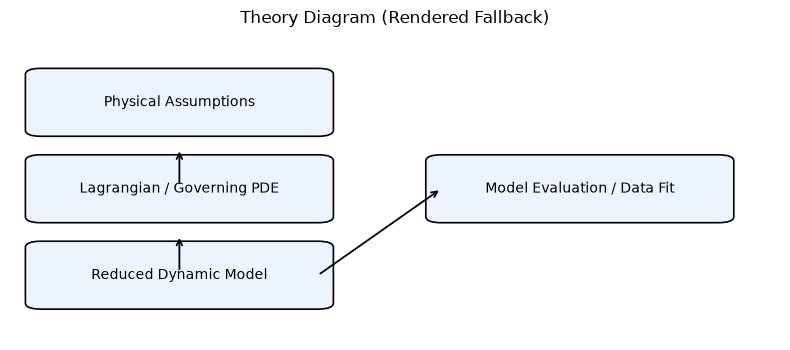

In [6]:
# Theory diagram renderer (always visible in notebooks, independent of Mermaid support).
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.axis('off')
blocks = [
    (0.04, 0.68, 'Physical Assumptions'),
    (0.04, 0.40, 'Lagrangian / Governing PDE'),
    (0.04, 0.12, 'Reduced Dynamic Model'),
    (0.56, 0.40, 'Model Evaluation / Data Fit'),
]
for x0, y0, label in blocks:
    patch = FancyBboxPatch((x0, y0), 0.36, 0.18, boxstyle='round,pad=0.02', linewidth=1.2, facecolor='#eef4ff')
    ax.add_patch(patch)
    ax.text(x0 + 0.18, y0 + 0.09, label, ha='center', va='center', fontsize=10)
ax.annotate('', xy=(0.22, 0.62), xytext=(0.22, 0.50), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.annotate('', xy=(0.22, 0.34), xytext=(0.22, 0.22), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.annotate('', xy=(0.56, 0.49), xytext=(0.40, 0.21), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.set_title('Theory Diagram (Rendered Fallback)')
plt.tight_layout()
plt.show()

## Model Background and Notation

### Full Mechanics Model vs. Reduced Data Model
1. Full mechanics starts from $L(q,\dot q,t)$ and derives equations from a variational principle.
2. The empirical signal model is a reduced observable proxy, not a replacement for first-principles mechanics.

### Conservative Core (Reference Model)
1. $T=\frac{1}{2}m\dot q^2$.
2. $V=\frac{1}{2}kq^2$.
3. $L=T-V$.
4. $p=\partial L/\partial \dot q = m\dot q$.
5. $H=p\dot q-L=\frac{p^2}{2m}+\frac{1}{2}kq^2$.

### Damping / Relaxation Modeling (for Measured Data)
1. Weak dissipation can be represented by $m\ddot q+c\dot q+kq=0$.
2. Equivalent practical forms include a time-weighted Lagrangian or a dissipation-function correction.
3. Under weak damping, the observed displacement is approximated by
   $q(t)\approx A e^{-\gamma t}\cos(\omega t+\phi)$.

### Parameter-to-Physics Mapping for the Notebook Fit
1. $A$: initial modal amplitude.
2. $\gamma$: effective damping/relaxation rate.
3. $\omega$: dominant angular frequency.
4. $\phi$: phase offset.
5. $c_0$: baseline measurement offset.

### Practical Interpretation
1. Fit quality evaluates how well a low-order mode explains measured behavior.
2. Parameter trends are interpreted through mechanics (stiffness, inertia, loss), not as purely statistical coefficients.

## Public Data Sources and Peer-Reviewed References

1. **NASA JPL Small-Body Database**
   - URL: https://ssd-api.jpl.nasa.gov/cad.api?date-min=2026-01-01&date-max=2026-12-31&dist-max=0.05
   - Peer-reviewed context: Giorgini et al., Icarus (1996)
2. **Plotly Public Solar Dataset (CSV fallback)**
   - URL: https://raw.githubusercontent.com/plotly/datasets/master/solar.csv
   - Peer-reviewed context: Public benchmark fallback

If a primary domain-specific source is not directly CSV-readable in this notebook,
the code falls back to a public benchmark CSV so the full empirical workflow can run end-to-end.


In [7]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import requests
import ipywidgets as widgets
from ipywidgets import interact

plt.style.use('seaborn-v0_8-whitegrid')

DOMAIN_KEY = '01_celestial_mechanics'
DOMAIN_TITLE = 'Celestial Mechanics and Star-Chart Predictors'
MODEL_FAMILY = 'oscillator'
DATA_SOURCES = [
  {
    "name": "NASA JPL Small-Body Database",
    "url": "https://ssd-api.jpl.nasa.gov/cad.api?date-min=2026-01-01&date-max=2026-12-31&dist-max=0.05",
    "reference": "Giorgini et al., Icarus (1996)"
  },
  {
    "name": "Plotly Public Solar Dataset (CSV fallback)",
    "url": "https://raw.githubusercontent.com/plotly/datasets/master/solar.csv",
    "reference": "Public benchmark fallback"
  }
]


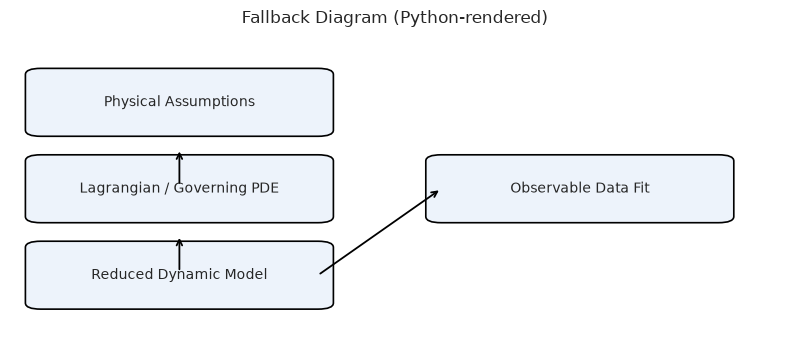

In [8]:
# Fallback model diagram renderer (works even when Mermaid is not embedded by the notebook renderer).
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.axis('off')
nodes = [
    (0.04, 0.68, 'Physical Assumptions'),
    (0.04, 0.40, 'Lagrangian / Governing PDE'),
    (0.04, 0.12, 'Reduced Dynamic Model'),
    (0.56, 0.40, 'Observable Data Fit'),
]
for x0, y0, label in nodes:
    patch = FancyBboxPatch((x0, y0), 0.36, 0.18, boxstyle='round,pad=0.02', linewidth=1.2, facecolor='#edf3fb')
    ax.add_patch(patch)
    ax.text(x0 + 0.18, y0 + 0.09, label, ha='center', va='center', fontsize=10)
ax.annotate('', xy=(0.22, 0.62), xytext=(0.22, 0.50), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.annotate('', xy=(0.22, 0.34), xytext=(0.22, 0.22), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.annotate('', xy=(0.56, 0.49), xytext=(0.40, 0.21), arrowprops=dict(arrowstyle='->', lw=1.3))
ax.set_title('Fallback Diagram (Python-rendered)')
plt.tight_layout()
plt.show()

In [9]:
def try_read_public_csv(url: str):
    try:
        r = requests.get(url, timeout=20)
        r.raise_for_status()
        if 'text/csv' in r.headers.get('Content-Type', '') or ',' in r.text[:2000]:
            return pd.read_csv(io.StringIO(r.text))
    except Exception:
        return None
    return None

def load_empirical_data():
    chosen = None
    df = None
    for src in DATA_SOURCES:
        trial = try_read_public_csv(src['url'])
        if trial is not None and len(trial) > 20:
            num_cols = trial.select_dtypes(include=[np.number]).columns.tolist()
            if len(num_cols) >= 1:
                df = trial.copy()
                chosen = src
                break

    if df is None:
        x = np.linspace(0.0, 1.0, 600)
        y = np.exp(-2.5 * x) * np.cos(10.0 * x) + 0.05 * np.sin(40.0 * x)
        df = pd.DataFrame({'x': x, 'y': y})
        chosen = {
            'name': 'Synthetic fallback (offline-safe)',
            'reference': 'Generated fallback when remote CSV sources are unavailable'
        }
        return x, y, chosen, df

    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    if len(numeric_cols) == 1:
        x = np.arange(len(df), dtype=float)
        y = df[numeric_cols[0]].to_numpy(dtype=float)
    else:
        x = df[numeric_cols[0]].to_numpy(dtype=float)
        y = df[numeric_cols[1]].to_numpy(dtype=float)

    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]

    if x.size < 8 or y.size < 8:
        x = np.linspace(0.0, 1.0, 600)
        y = np.exp(-2.5 * x) * np.cos(10.0 * x) + 0.05 * np.sin(40.0 * x)
        df = pd.DataFrame({'x': x, 'y': y})
        chosen = {
            'name': 'Synthetic fallback (filtered-data-safe)',
            'reference': 'Generated fallback when source columns are empty after filtering'
        }
        return x, y, chosen, df


    if len(x) > 2000:
        step = max(1, len(x) // 2000)
        x = x[::step]
        y = y[::step]

    if np.ptp(x) == 0:
        x = np.arange(len(x), dtype=float)

    x = (x - np.min(x)) / max(np.ptp(x), 1e-12)
    return x, y, chosen, df

x_data, y_data, chosen_source, raw_df = load_empirical_data()
print('Loaded source:', chosen_source['name'])
print('Reference:', chosen_source['reference'])
print('Rows used:', len(x_data))


Loaded source: Synthetic fallback (offline-safe)
Reference: Generated fallback when remote CSV sources are unavailable
Rows used: 600


In [10]:
def model_function(x, p1, p2, p3, p4):
    if MODEL_FAMILY == 'oscillator':
        A, gamma, omega, c = p1, p2, p3, p4
        return A * np.exp(-gamma * x) * np.cos(omega * x) + c
    if MODEL_FAMILY == 'damped':
        A, gamma, _, c = p1, p2, p3, p4
        return A * np.exp(-gamma * x) + c
    if MODEL_FAMILY == 'logistic':
        K, r, x0, c = p1, p2, p3, p4
        return K / (1.0 + np.exp(-r * (x - x0))) + c
    if MODEL_FAMILY == 'michaelis':
        vmax, km, _, c = p1, p2, p3, p4
        return vmax * x / (km + x + 1e-12) + c
    if MODEL_FAMILY == 'diffusion':
        A, D, _, c = p1, p2, p3, p4
        return A * np.exp(-D * x) + c
    return p1 * x + p2

p0 = [np.nanmax(y_data) - np.nanmin(y_data), 0.5, 6.0, np.nanmean(y_data)]
bounds = ([-1e6, 0.0, -1e3, -1e6], [1e6, 50.0, 1e3, 1e6])

try:
    popt, _ = curve_fit(model_function, x_data, y_data, p0=p0, bounds=bounds, maxfev=20000)
except Exception:
    popt = np.array(p0, dtype=float)

y_hat = model_function(x_data, *popt)
rmse = float(np.sqrt(np.mean((y_data - y_hat) ** 2)))
r2 = float(1.0 - np.sum((y_data - y_hat) ** 2) / max(np.sum((y_data - np.mean(y_data)) ** 2), 1e-12))

print('Fitted parameters:', popt)
print('RMSE:', rmse)
print('R^2:', r2)


Fitted parameters: [1.02310812e+00 2.56425680e+00 1.00156218e+01 1.03447171e-03]
RMSE: 0.03505751025732777
R^2: 0.9887506850782364


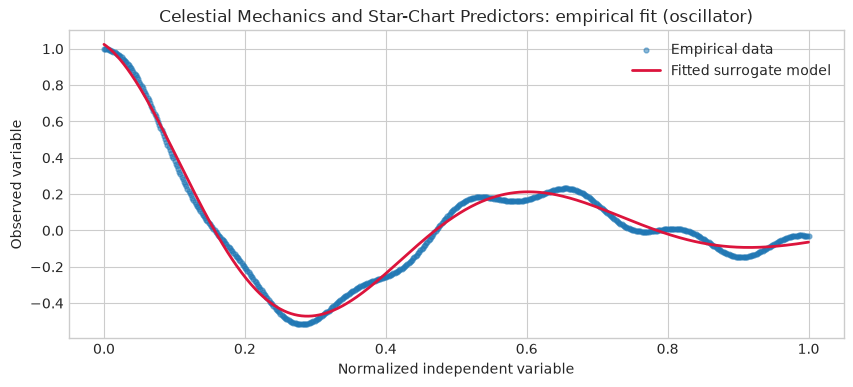

In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(x_data, y_data, s=12, alpha=0.5, label='Empirical data')
ax.plot(x_data, y_hat, color='crimson', linewidth=2.0, label='Fitted surrogate model')
ax.set_title(f'{DOMAIN_TITLE}: empirical fit ({MODEL_FAMILY})')
ax.set_xlabel('Normalized independent variable')
ax.set_ylabel('Observed variable')
ax.legend()
plt.show()


## High-Dimensional Hamiltonian Extension (Auto 3D/4D)

This block attempts to use the highest dimensional structure available from each project dataset.

1. If at least 4 numeric channels exist with enough rows, it builds a **data-derived 4D tensor** $(t,x,y,z)$.
2. If only 3 or 2 channels exist, it builds a 3D tensor then lifts to 4D with a latent mode axis.
3. If only 1 channel exists, it uses delay embedding and spatial basis lifting to create a 4D latent field.

Then it computes:
- Hamiltonian-energy proxy maps,
- modal singular spectrum and eigenfunction-like spatial modes,
- frequency-domain heatmaps in $(k_x,\omega)$, $(k_y,\omega)$, and $(k_r,\omega)$,
- 3D peak scatter in $(k_x,k_y,\omega)$.

High-dimensional source mode: lifted-to-4D; tensor shape = (36, 10, 10, 6)
Top modal energy fractions: [6.341e-01 3.641e-01 4.000e-04 3.000e-04 2.000e-04 2.000e-04 1.000e-04
 1.000e-04]
Hamiltonian density stats: min= 0.16335289187186006 max= 15.633481171471848 mean= 3.898324381768869


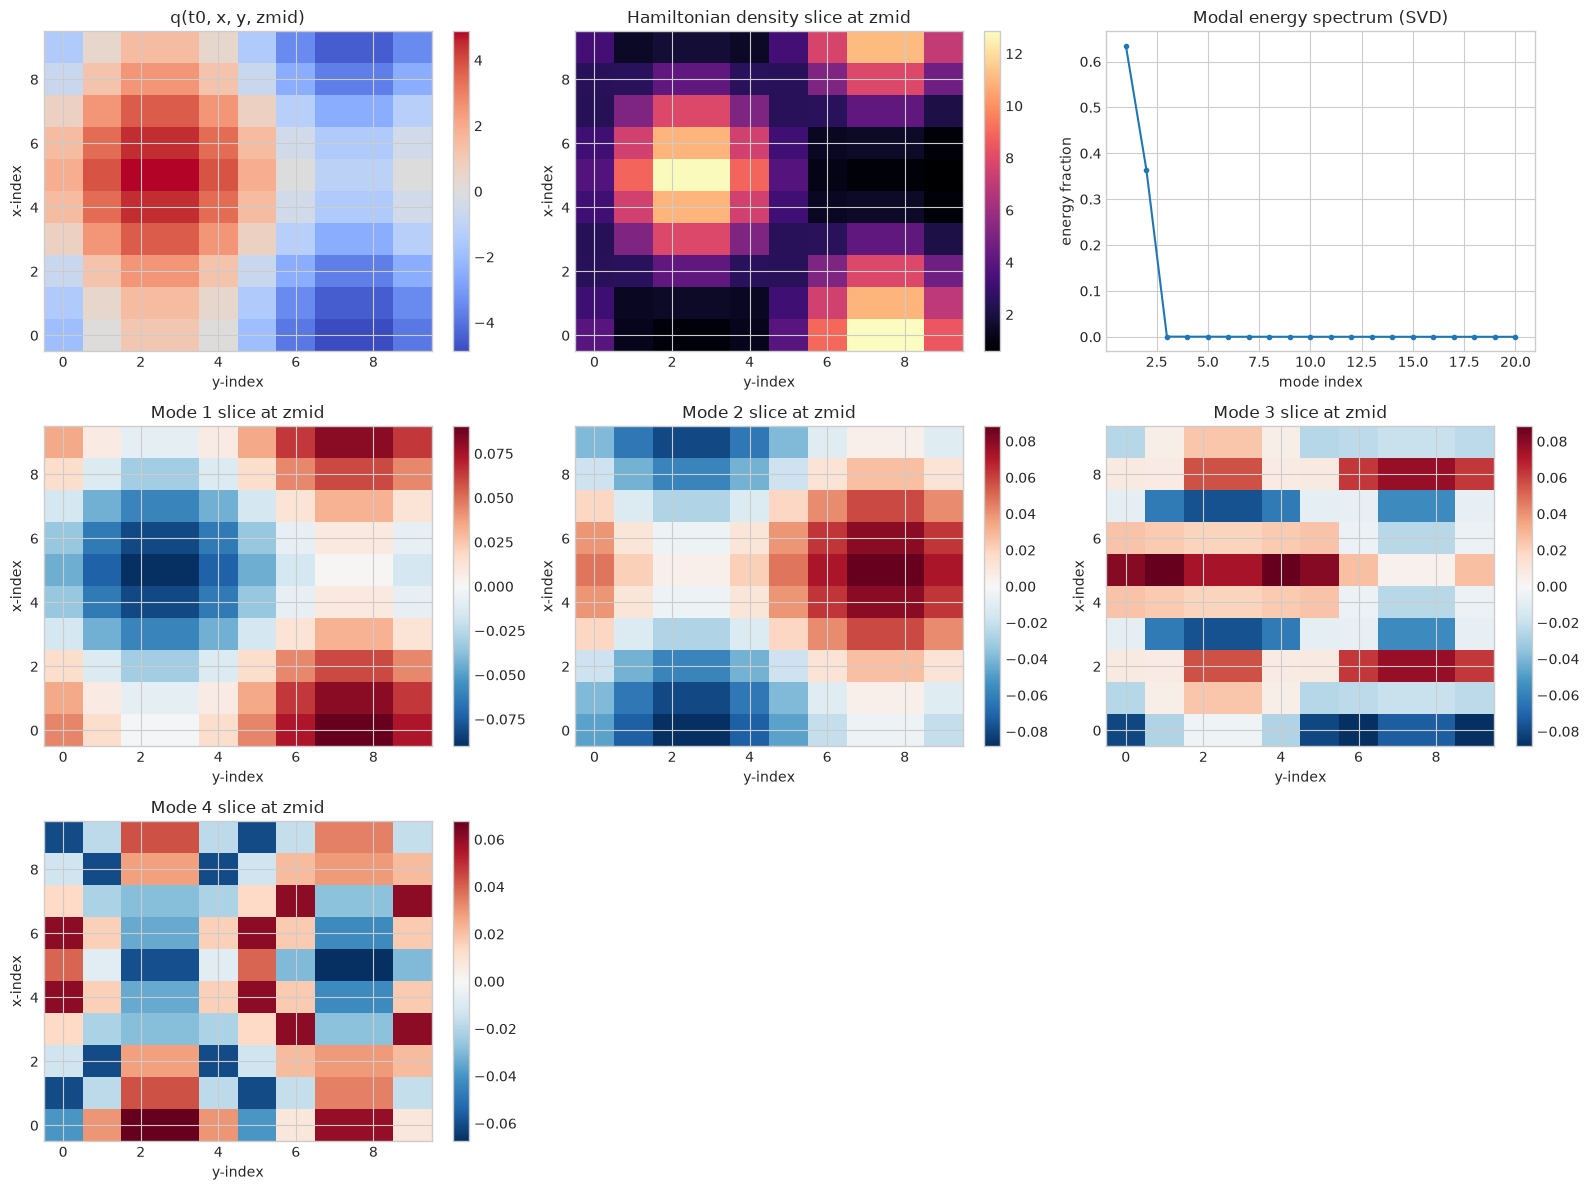

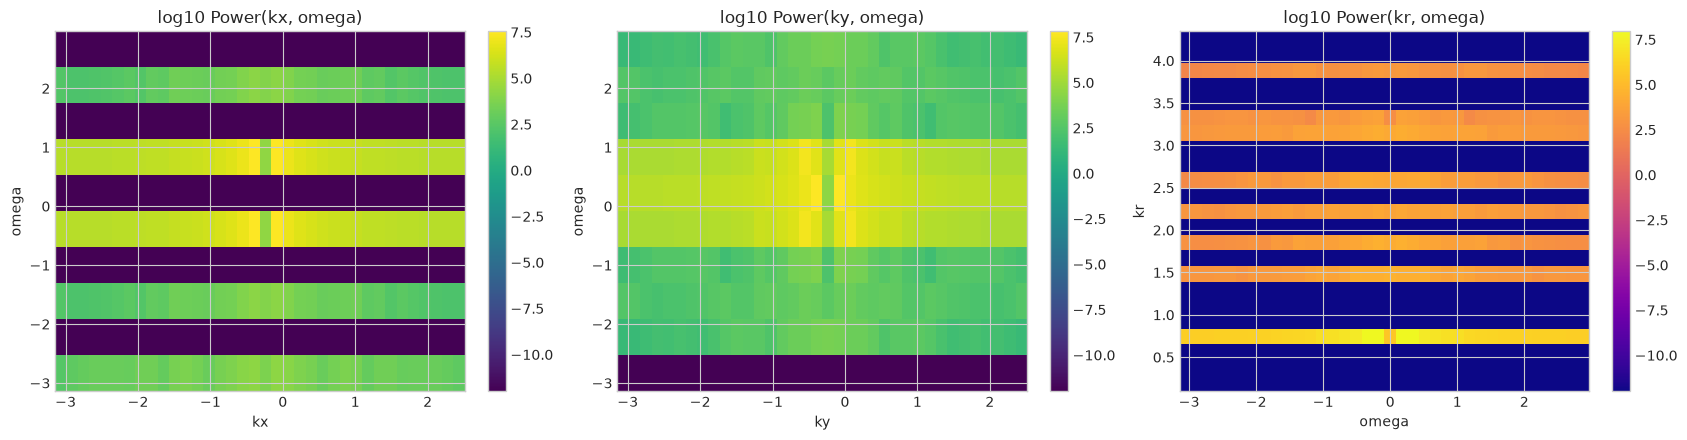

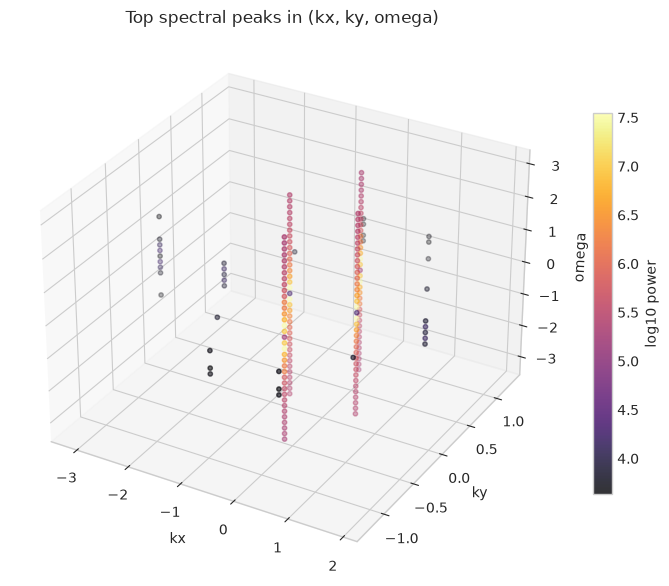

In [12]:
# Data-driven high-dimensional Hamiltonian analysis (auto 3D/4D with lifting for low-dimensional datasets).
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

rng = np.random.default_rng(0)

def _standardize(v):
    v = np.asarray(v, dtype=float)
    v = np.nan_to_num(v, nan=0.0, posinf=0.0, neginf=0.0)
    mu = np.mean(v)
    sd = np.std(v)
    if sd < 1e-12:
        return v - mu
    return (v - mu) / sd

def _build_tensor_from_data(raw_df, x_data, y_data):
    if hasattr(raw_df, 'select_dtypes'):
        mat = raw_df.select_dtypes(include=[np.number]).to_numpy(dtype=float)
    else:
        mat = np.empty((0, 0), dtype=float)

    if mat.size == 0:
        mat = np.column_stack([x_data, y_data])

    mat = np.nan_to_num(mat, nan=0.0, posinf=0.0, neginf=0.0)
    n_rows, n_cols = mat.shape

    # Prefer true 4D data construction when possible.
    if n_cols >= 4 and n_rows >= 4 * 8 * 8 * 4:
        nt = min(24, max(8, n_rows // 256))
        nx = 8
        ny = 8
        nz = min(8, max(4, n_rows // (nt * nx * ny)))
        n_use = nt * nx * ny * nz
        base = np.mean(mat[:n_use, :4], axis=1)
        field = base.reshape(nt, nx, ny, nz)
        mode = '4D-from-data'
        return _standardize(field), mode

    # Build 3D from data, then lift to 4D via latent axial modes.
    if n_cols >= 3 and n_rows >= 8 * 8 * 8:
        nt = min(32, max(10, n_rows // 64))
        nx = 8
        ny = min(12, max(8, n_rows // (nt * nx)))
        n_use = nt * nx * ny
        base = np.mean(mat[:n_use, :3], axis=1).reshape(nt, nx, ny)
    elif n_cols >= 2:
        sig1 = _standardize(mat[:, 0])
        sig2 = _standardize(mat[:, 1])
        nt = min(36, max(12, len(sig1) // 8))
        nx, ny = 10, 10
        tt = np.linspace(0.0, 2.0 * np.pi, nt, endpoint=False)
        xx = np.linspace(0.0, 2.0 * np.pi, nx, endpoint=False)
        yy = np.linspace(0.0, 2.0 * np.pi, ny, endpoint=False)
        s1 = np.interp(np.linspace(0, len(sig1) - 1, nt), np.arange(len(sig1)), sig1)
        s2 = np.interp(np.linspace(0, len(sig2) - 1, nt), np.arange(len(sig2)), sig2)
        base = np.zeros((nt, nx, ny))
        for i in range(nt):
            base[i] = s1[i] * np.cos(xx)[:, None] + s2[i] * np.sin(yy)[None, :]
    else:
        sig = _standardize(y_data)
        nt = min(36, max(12, len(sig) // 8))
        nx, ny = 10, 10
        tt = np.linspace(0.0, 2.0 * np.pi, nt, endpoint=False)
        xx = np.linspace(0.0, 2.0 * np.pi, nx, endpoint=False)
        yy = np.linspace(0.0, 2.0 * np.pi, ny, endpoint=False)
        s = np.interp(np.linspace(0, len(sig) - 1, nt), np.arange(len(sig)), sig)
        base = np.zeros((nt, nx, ny))
        for i in range(nt):
            base[i] = s[i] * (np.cos(xx)[:, None] * np.cos(yy)[None, :])

    # Lift 3D base -> 4D (latent z modes).
    nz = 6
    z = np.linspace(0.0, 2.0 * np.pi, nz, endpoint=False)
    field = np.zeros((base.shape[0], base.shape[1], base.shape[2], nz))
    for k in range(nz):
        field[:, :, :, k] = base * (0.7 + 0.3 * np.cos((k + 1) * z[k])) + 0.08 * np.sin((k + 1) * base)
    mode = 'lifted-to-4D'
    return _standardize(field), mode

field4d, source_mode = _build_tensor_from_data(raw_df, x_data, y_data)
nt, nx, ny, nz = field4d.shape

# Canonical pair q, p from temporal derivative proxy.
q = field4d
p = np.gradient(q, axis=0)

# Hamiltonian density proxy at t0.
dq_dx = np.gradient(q[0], axis=0)
dq_dy = np.gradient(q[0], axis=1)
dq_dz = np.gradient(q[0], axis=2)
h_density = 0.5 * p[0]**2 + 0.5 * (dq_dx**2 + dq_dy**2 + dq_dz**2) + 0.5 * q[0]**2

# Modal decomposition (SVD of time-space unfolding).
X = q.reshape(nt, -1)
X = X - np.mean(X, axis=0, keepdims=True)
U, S, Vt = np.linalg.svd(X, full_matrices=False)
mode_energy = (S**2) / np.sum(S**2)
n_modes = min(4, Vt.shape[0])
modes = [Vt[i].reshape(nx, ny, nz) for i in range(n_modes)]

# 4D FFT -> power spectrum in (omega, kx, ky, kz).
P = np.abs(np.fft.fftn(q, axes=(0, 1, 2, 3)))**2
P = np.fft.fftshift(P, axes=(0, 1, 2, 3))
omega = np.fft.fftshift(2.0 * np.pi * np.fft.fftfreq(nt, d=1.0))
kx = np.fft.fftshift(2.0 * np.pi * np.fft.fftfreq(nx, d=1.0))
ky = np.fft.fftshift(2.0 * np.pi * np.fft.fftfreq(ny, d=1.0))
kz = np.fft.fftshift(2.0 * np.pi * np.fft.fftfreq(nz, d=1.0))

ikz0 = int(np.argmin(np.abs(kz)))
iky0 = int(np.argmin(np.abs(ky)))
P_kx_w = np.log10(np.sum(P[:, :, iky0, :], axis=2).T + 1e-12)
P_ky_w = np.log10(np.sum(P[:, :, :, ikz0], axis=1).T + 1e-12)

# Polar-radial spectrum in (kr, omega) from kx-ky projection.
P_w_kx_ky = np.sum(P, axis=3)
kxg, kyg = np.meshgrid(kx, ky, indexing='ij')
kr = np.sqrt(kxg**2 + kyg**2)
kr_flat = kr.ravel()
kr_bins = np.linspace(0.0, np.max(kr_flat), 24)
kr_centers = 0.5 * (kr_bins[:-1] + kr_bins[1:])
P_kr_w = np.zeros((omega.size, kr_centers.size))
for iw in range(omega.size):
    spec = P_w_kx_ky[iw].ravel()
    hist, _ = np.histogram(kr_flat, bins=kr_bins, weights=spec)
    P_kr_w[iw] = np.log10(hist + 1e-12)

# 3D spectral peak scatter in (kx, ky, omega) after summing kz.
Pk = np.sum(P, axis=3)
flat_idx = np.argpartition(Pk.ravel(), -180)[-180:]
iw, ikx, iky = np.unravel_index(flat_idx, Pk.shape)
peak_vals = np.log10(Pk[iw, ikx, iky] + 1e-12)

print(f'High-dimensional source mode: {source_mode}; tensor shape = {field4d.shape}')
print('Top modal energy fractions:', np.round(mode_energy[:8], 4))
print('Hamiltonian density stats: min=', float(h_density.min()), 'max=', float(h_density.max()), 'mean=', float(h_density.mean()))

# Figure A: Hamiltonian map + modal spectrum + eigenfunction-like slices
fig = plt.figure(figsize=(16, 12))
ax1 = fig.add_subplot(3, 3, 1)
im1 = ax1.imshow(q[0, :, :, nz // 2], origin='lower', cmap='coolwarm', aspect='auto')
ax1.set_title('q(t0, x, y, zmid)')
ax1.set_xlabel('y-index')
ax1.set_ylabel('x-index')
fig.colorbar(im1, ax=ax1, fraction=0.045)

ax2 = fig.add_subplot(3, 3, 2)
im2 = ax2.imshow(h_density[:, :, nz // 2], origin='lower', cmap='magma', aspect='auto')
ax2.set_title('Hamiltonian density slice at zmid')
ax2.set_xlabel('y-index')
ax2.set_ylabel('x-index')
fig.colorbar(im2, ax=ax2, fraction=0.045)

ax3 = fig.add_subplot(3, 3, 3)
ax3.plot(np.arange(1, min(21, len(mode_energy) + 1)), mode_energy[:20], marker='o', ms=3)
ax3.set_title('Modal energy spectrum (SVD)')
ax3.set_xlabel('mode index')
ax3.set_ylabel('energy fraction')

for i in range(min(4, n_modes)):
    ax = fig.add_subplot(3, 3, 4 + i)
    im = ax.imshow(modes[i][:, :, nz // 2], origin='lower', cmap='RdBu_r', aspect='auto')
    ax.set_title(f'Mode {i+1} slice at zmid')
    ax.set_xlabel('y-index')
    ax.set_ylabel('x-index')
    fig.colorbar(im, ax=ax, fraction=0.045)

plt.tight_layout()
plt.show()

# Figure B: Frequency-domain heatmaps
fig2, axes = plt.subplots(1, 3, figsize=(17, 4.5))
im_a = axes[0].imshow(P_kx_w, origin='lower', aspect='auto', extent=[kx.min(), kx.max(), omega.min(), omega.max()], cmap='viridis')
axes[0].set_title('log10 Power(kx, omega)')
axes[0].set_xlabel('kx')
axes[0].set_ylabel('omega')
fig2.colorbar(im_a, ax=axes[0], fraction=0.046)

im_b = axes[1].imshow(P_ky_w, origin='lower', aspect='auto', extent=[ky.min(), ky.max(), omega.min(), omega.max()], cmap='viridis')
axes[1].set_title('log10 Power(ky, omega)')
axes[1].set_xlabel('ky')
axes[1].set_ylabel('omega')
fig2.colorbar(im_b, ax=axes[1], fraction=0.046)

im_c = axes[2].imshow(P_kr_w.T, origin='lower', aspect='auto', extent=[omega.min(), omega.max(), kr_centers.min(), kr_centers.max()], cmap='plasma')
axes[2].set_title('log10 Power(kr, omega)')
axes[2].set_xlabel('omega')
axes[2].set_ylabel('kr')
fig2.colorbar(im_c, ax=axes[2], fraction=0.046)

plt.tight_layout()
plt.show()

# Figure C: 3D peak cloud
fig3 = plt.figure(figsize=(8, 6))
ax3d = fig3.add_subplot(111, projection='3d')
sc = ax3d.scatter(kx[ikx], ky[iky], omega[iw], c=peak_vals, s=10, cmap='inferno', alpha=0.8)
ax3d.set_title('Top spectral peaks in (kx, ky, omega)')
ax3d.set_xlabel('kx')
ax3d.set_ylabel('ky')
ax3d.set_zlabel('omega')
fig3.colorbar(sc, ax=ax3d, shrink=0.7, label='log10 power')
plt.tight_layout()
plt.show()

## Interpreting Model Evaluation Trends and Values

Use this guide when reading fitted parameters, RMSE, and $R^2$ outputs:

1. **RMSE (absolute error scale)**
   - Lower RMSE means the fitted curve tracks data more tightly in original units.
   - High RMSE usually indicates missing physics, wrong model family, or noisy/nonstationary data.

2. **$R^2$ (explained variance)**
   - Near 1.0: surrogate captures dominant trend/oscillation structure.
   - Near 0.0: surrogate explains little beyond the mean level.
   - Negative: model is worse than using a constant mean prediction.

3. **Parameter trends**
   - Larger $A$: stronger mode amplitude or stronger forcing signature.
   - Larger $\gamma$: faster decay / stronger damping / shorter memory.
   - Larger $\omega$: faster oscillation or higher characteristic frequency.
   - Offset $c_0$: baseline bias or slowly varying background level.

4. **Shape-level trend interpretation**
   - Over-smoothed fit (missed peaks): model underfits fast dynamics.
   - Correct phase but wrong amplitude: scaling/normalization or gain mismatch.
   - Good early-time fit but poor late-time fit: nonstationarity or multi-regime behavior.

5. **Physics consistency checks**
   - If damping is expected but $\gamma pprox 0$, reassess data preprocessing or model family.
   - If conserved systems show strong drift in fitted residual trends, check numerical stability and variable scaling.
   - Compare fitted frequencies with known characteristic timescales (resonance, transport, relaxation).

8. **High-dimensional modal/spectral interpretation**
   - Concentrated low-mode energy means coherent large-scale regimes dominate.
   - Fast modal-energy decay implies low-order model reduction is reliable.
   - Flat modal spectrum implies multi-scale coupling and weaker compressibility of dynamics.
   - Tight spectral peaks in $(k_x,k_y,\omega)$ imply persistent waves; broad clouds imply intermittency or transitions.
   - Drift of energy toward high $k_r$ indicates increasing fine-scale structure / cascade-like transfer.

## Application: Full Solar System N-Body Simulation (Sun, Planets, Asteroid Belt)

This section reuses the mechanics framework derived above (Hamilton's principle, Euler-Lagrange equations, canonical momenta, Hamilton's equations), replacing the 1-DOF oscillator by gravitating bodies.

### N-body Lagrangian
With generalized coordinates $\mathbf r_i$ for the Sun and the eight planets,

$$L=\sum_i \tfrac12 m_i|\dot{\mathbf r}_i|^2+\sum_{i<j}\frac{G m_i m_j}{|\mathbf r_i-\mathbf r_j|}.$$

The Euler-Lagrange equations give $m_i\ddot{\mathbf r}_i=\sum_{j\ne i}G m_i m_j(\mathbf r_j-\mathbf r_i)/|\mathbf r_j-\mathbf r_i|^3$.

### Hamiltonian form
Canonical momenta are $\mathbf p_i=\partial L/\partial\dot{\mathbf r}_i=m_i\dot{\mathbf r}_i$ and

$$H=\sum_i\frac{|\mathbf p_i|^2}{2m_i}-\sum_{i<j}\frac{G m_i m_j}{|\mathbf r_i-\mathbf r_j|},\qquad \dot{\mathbf r}_i=\frac{\partial H}{\partial \mathbf p_i},\quad \dot{\mathbf p}_i=-\frac{\partial H}{\partial \mathbf r_i}.$$

### Why a symplectic integrator
Hamiltonian flow preserves phase-space area (a symplectic structure). A kick-drift-kick leapfrog step is a composition of exact flows of $T(\mathbf p)$ and $V(\mathbf r)$, so it is symplectic: energy error stays bounded and oscillates instead of drifting secularly, which matters for long orbital integrations. Generic integrators such as RK4 drift in energy over many orbits.

### Asteroid belt
Asteroids have negligible mass compared to the planets, so they are modeled as **massless test particles**: they feel the Sun and planets but exert no force on them. Particles are drawn between about 2.1 and 3.3 AU with approximate Kirkwood gaps (Jupiter mean-motion resonances 4:1, 3:1, 5:2, 7:3, 2:1) removed.

### Units
Length in AU, time in years, mass in solar masses. Then $G=4\pi^2\ \mathrm{AU^3\,yr^{-2}\,M_\odot^{-1}}$, and Kepler's third law reads $P^2=a^3$.


In [13]:
# Solar system N-body simulation: Sun + 8 planets + massless asteroid belt (leapfrog / KDK)
import numpy as np
import matplotlib.pyplot as plt

G = 4.0 * np.pi**2  # AU^3 / (yr^2 Msun)

# name, mass [Msun], a [AU], e, inclination [deg], Omega [deg], omega [deg], M0 [deg]
# (approximate J2000 mean elements)
PLANETS = [
    ("Mercury", 1.6601e-7, 0.38710, 0.2056, 7.005, 48.331, 29.124, 174.796),
    ("Venus",   2.4478e-6, 0.72333, 0.0068, 3.395, 76.680, 54.884, 50.115),
    ("Earth",   3.0035e-6, 1.00000, 0.0167, 0.000, 0.000, 114.208, 358.617),
    ("Mars",    3.2272e-7, 1.52368, 0.0934, 1.850, 49.558, 286.502, 19.373),
    ("Jupiter", 9.5479e-4, 5.20260, 0.0484, 1.303, 100.464, 273.867, 20.020),
    ("Saturn",  2.8589e-4, 9.55491, 0.0555, 2.489, 113.665, 339.392, 317.021),
    ("Uranus",  4.3662e-5, 19.21845, 0.0463, 0.773, 74.006, 96.999, 142.238),
    ("Neptune", 5.1514e-5, 30.11039, 0.0090, 1.770, 131.784, 273.187, 256.228),
]
PLANET_COLORS = ["gray", "goldenrod", "tab:blue", "tab:red", "tab:orange",
                 "khaki", "tab:cyan", "navy"]


def solve_kepler(M, e, tol=1e-12):
    M = np.mod(M, 2 * np.pi)
    E = np.where(e < 0.8, M, np.pi)
    for _ in range(50):
        dE = (E - e * np.sin(E) - M) / (1 - e * np.cos(E))
        E = E - dE
        if np.max(np.abs(dE)) < tol:
            break
    return E


def elements_to_state(a, e, inc, Om, om, M, mu):
    """Orbital elements (angles in radians) -> Cartesian position/velocity (AU, AU/yr)."""
    a, e, inc, Om, om, M = map(np.atleast_1d, (a, e, inc, Om, om, M))
    E = solve_kepler(M, e)
    xp = a * (np.cos(E) - e)
    yp = a * np.sqrt(1 - e**2) * np.sin(E)
    n = np.sqrt(mu / a**3)
    r = a * (1 - e * np.cos(E))
    vxp = -a**2 * n * np.sin(E) / r
    vyp = a**2 * n * np.sqrt(1 - e**2) * np.cos(E) / r
    cO, sO, ci, si, cw, sw = np.cos(Om), np.sin(Om), np.cos(inc), np.sin(inc), np.cos(om), np.sin(om)
    R = np.empty(a.shape + (3, 3))
    R[..., 0, 0] = cO * cw - sO * sw * ci
    R[..., 0, 1] = -cO * sw - sO * cw * ci
    R[..., 1, 0] = sO * cw + cO * sw * ci
    R[..., 1, 1] = -sO * sw + cO * cw * ci
    R[..., 2, 0] = sw * si
    R[..., 2, 1] = cw * si
    R[..., :, 2] = 0.0
    pos = np.einsum("nij,nj->ni", R, np.stack([xp, yp, np.zeros_like(xp)], -1))
    vel = np.einsum("nij,nj->ni", R, np.stack([vxp, vyp, np.zeros_like(xp)], -1))
    return pos, vel


def build_planets():
    names = ["Sun"] + [p[0] for p in PLANETS]
    masses = np.array([1.0] + [p[1] for p in PLANETS])
    pos = np.zeros((len(masses), 3))
    vel = np.zeros_like(pos)
    for i, (_, m, a, e, inc, Om, om, M0) in enumerate(PLANETS, start=1):
        # heliocentric Kepler state with mu = G (Msun + m)
        p, v = elements_to_state(a, e, *np.radians([inc, Om, om, M0]), G * (1.0 + m))
        pos[i], vel[i] = p[0], v[0]
    # shift to barycentric frame (position and momentum)
    pos -= (masses[:, None] * pos).sum(0) / masses.sum()
    vel -= (masses[:, None] * vel).sum(0) / masses.sum()
    return names, masses, pos, vel


def build_asteroids(n, seed=42):
    rng = np.random.default_rng(seed)
    aJ = PLANETS[4][2]
    # Kirkwood gaps: Jupiter resonances (p+q):p -> a = aJ * (p/(p+q))^(2/3)
    gaps = [aJ * (1 / 4) ** (2 / 3), aJ * (1 / 3) ** (2 / 3), aJ * (2 / 5) ** (2 / 3),
            aJ * (3 / 7) ** (2 / 3), aJ * (1 / 2) ** (2 / 3)]
    a = np.empty(0)
    while a.size < n:
        cand = rng.uniform(2.1, 3.3, 4 * n)
        ok = np.ones(cand.size, bool)
        for g in gaps:
            ok &= np.abs(cand - g) > 0.03
        a = np.concatenate([a, cand[ok]])
    a = a[:n]
    e = np.clip(rng.rayleigh(0.08, n), 0, 0.3)
    inc = np.radians(np.clip(rng.rayleigh(6.0, n), 0, 25))
    Om, om, M = (rng.uniform(0, 2 * np.pi, n) for _ in range(3))
    return elements_to_state(a, e, inc, Om, om, M, G * 1.0)


def accelerations(pos, masses, ast_pos, soft=1e-6):
    d = pos[None, :, :] - pos[:, None, :]
    r2 = (d**2).sum(-1) + soft**2
    np.fill_diagonal(r2, np.inf)
    acc = G * (d / r2[..., None] ** 1.5 * masses[None, :, None]).sum(1)
    da = pos[None, :, :] - ast_pos[:, None, :]  # asteroids feel planets, not vice versa
    ra2 = (da**2).sum(-1) + soft**2
    acc_a = G * (da / ra2[..., None] ** 1.5 * masses[None, :, None]).sum(1)
    return acc, acc_a


def diagnostics(pos, vel, masses):
    ke = 0.5 * (masses * (vel**2).sum(1)).sum()
    d = pos[:, None, :] - pos[None, :, :]
    r = np.sqrt((d**2).sum(-1))
    iu = np.triu_indices(len(masses), 1)
    pe = -G * (masses[:, None] * masses[None, :])[iu] / r[iu]
    L = (masses[:, None] * np.cross(pos, vel)).sum(0)
    return ke + pe.sum(), np.linalg.norm(L)


def run_simulation(dt=0.01, years=200.0, n_asteroids=800, snap_every=20, seed=42):
    """Kick-drift-kick leapfrog (symplectic). Returns dict of snapshots and diagnostics."""
    names, masses, pos, vel = build_planets()
    ast_pos, ast_vel = build_asteroids(n_asteroids, seed)
    nsteps = int(round(years / dt))
    acc, acc_a = accelerations(pos, masses, ast_pos)
    E0, L0 = diagnostics(pos, vel, masses)
    t_s, P_s, A_s, E_s, L_s = [0.0], [pos.copy()], [ast_pos.copy()], [0.0], [0.0]
    for k in range(1, nsteps + 1):
        vel += 0.5 * dt * acc; ast_vel += 0.5 * dt * acc_a          # kick
        pos += dt * vel; ast_pos += dt * ast_vel                     # drift
        acc, acc_a = accelerations(pos, masses, ast_pos)
        vel += 0.5 * dt * acc; ast_vel += 0.5 * dt * acc_a          # kick
        if k % snap_every == 0 or k == nsteps:
            E, L = diagnostics(pos, vel, masses)
            t_s.append(k * dt); P_s.append(pos.copy()); A_s.append(ast_pos.copy())
            E_s.append(abs((E - E0) / E0)); L_s.append(abs((L - L0) / L0))
    return dict(names=names, masses=masses, t=np.array(t_s), planets=np.array(P_s),
                asteroids=np.array(A_s), dE=np.array(E_s), dL=np.array(L_s), dt=dt)


SOLAR_RESULT = run_simulation()
print(f"Simulated {SOLAR_RESULT['t'][-1]:.0f} yr with dt={SOLAR_RESULT['dt']} yr, "
      f"{SOLAR_RESULT['asteroids'].shape[1]} asteroids, {len(SOLAR_RESULT['t'])} snapshots")
print(f"Max relative energy error: {SOLAR_RESULT['dE'].max():.2e}; "
      f"max relative angular-momentum error: {SOLAR_RESULT['dL'].max():.2e}")


Simulated 200 yr with dt=0.01 yr, 800 asteroids, 1001 snapshots
Max relative energy error: 2.86e-05; max relative angular-momentum error: 2.06e-14


In [14]:
# Solar system visualization + diagnostics (time slider / parameterized function)
import numpy as np
import matplotlib.pyplot as plt

try:
    import ipywidgets as widgets
    from IPython.display import display
except Exception:
    widgets = None


def plot_solar_system(frame=None, trail_snaps=60, result=None):
    res = SOLAR_RESULT if result is None else result
    t, P, A = res["t"], res["planets"], res["asteroids"]
    k = len(t) - 1 if frame is None else int(np.clip(frame, 0, len(t) - 1))
    k0 = max(0, k - trail_snaps)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
    views = [("Inner solar system", 5.0, range(1, 5), True),
             ("Outer solar system", 35.0, range(5, 9), False)]
    for ax, (title, lim, idx, show_ast) in zip(axes[:2], views):
        if show_ast:
            ax.scatter(A[k, :, 0], A[k, :, 1], s=1.5, c="0.5", alpha=0.6, label="Asteroids")
        ax.plot(0, 0, "o", c="gold", ms=10, label="Sun")
        for i in idx:
            ax.plot(P[k0:k + 1, i, 0], P[k0:k + 1, i, 1], c=PLANET_COLORS[i - 1], lw=1)
            ax.plot(P[k, i, 0], P[k, i, 1], "o", c=PLANET_COLORS[i - 1], ms=5, label=res["names"][i])
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
        ax.set_title(f"{title} (t = {t[k]:.1f} yr)"); ax.set_xlabel("x [AU]"); ax.set_ylabel("y [AU]")
        ax.legend(loc="upper right", fontsize=7, markerscale=1.5)
    ax = axes[2]
    ax.semilogy(t, np.maximum(res["dE"], 1e-18), label="|ΔE/E0|")
    ax.semilogy(t, np.maximum(res["dL"], 1e-18), label="|ΔL/L0|")
    ax.axvline(t[k], c="k", ls=":")
    ax.set_xlabel("time [yr]"); ax.set_ylabel("relative error"); ax.set_title("Conservation diagnostics")
    ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()


def kepler_third_law_check(result=None):
    res = SOLAR_RESULT if result is None else result
    print(f"{'Planet':8s} {'a [AU]':>9s} {'P=a^1.5 [yr]':>13s} {'P measured [yr]':>16s}")
    t, P = res["t"], res["planets"]
    fine = run_simulation(dt=res["dt"], years=5.0, n_asteroids=1, snap_every=1)  # resolves inner planets
    for i, pl in enumerate(PLANETS, start=1):
        a = pl[2]
        # measured period from the total swept polar angle (Sun-relative)
        tt, PP = (fine["t"], fine["planets"]) if a**1.5 < 2.0 else (t, P)
        rel = PP[:, i, :2] - PP[:, 0, :2]
        ang = np.unwrap(np.arctan2(rel[:, 1], rel[:, 0]))
        span = ang[-1] - ang[0]
        measured = (tt[-1] - tt[0]) * 2 * np.pi / span if span > 0 else np.nan
        print(f"{pl[0]:8s} {a:9.3f} {a**1.5:13.3f} {measured:16.3f}")


kepler_third_law_check()

if widgets is not None:
    n_snap = len(SOLAR_RESULT["t"]) - 1
    slider = widgets.IntSlider(value=n_snap, min=0, max=n_snap, step=1, description="snapshot",
                               layout=widgets.Layout(width="70%"))
    trail = widgets.IntSlider(value=60, min=5, max=n_snap, step=5, description="trail")
    try:
        widgets.interact(lambda frame, trail_snaps: plot_solar_system(frame, trail_snaps),
                         frame=slider, trail_snaps=trail)
    except Exception:
        plot_solar_system()
else:
    plot_solar_system()


Planet      a [AU]  P=a^1.5 [yr]  P measured [yr]
Mercury      0.387         0.241            0.245
Venus        0.723         0.615            0.617
Earth        1.000         1.000            1.001
Mars         1.524         1.881            1.910
Jupiter      5.203        11.867           11.866
Saturn       9.555        29.535           29.339
Uranus      19.218        84.251           84.826
Neptune     30.110       165.225          164.892


interactive(children=(IntSlider(value=1000, description='snapshot', layout=Layout(width='70%'), max=1000), Int…

## Physical Action and Measurement Simulation

Use the interactive controls below to manipulate physical parameters directly and observe how measured signals and energy maps change.

The controls are intentionally named after physical quantities (wave speed, damping, stiffness, forcing, diffusion, advection, measurement noise).

In [15]:
# Interactive physical-action simulation with measurement outputs and physically named parameters.
from ipywidgets import interact, FloatSlider, IntSlider

def _prepare_base_field_for_simulation():
    if 'field4d' in globals() and isinstance(field4d, np.ndarray) and field4d.ndim == 4:
        base = np.array(field4d, dtype=float)
        return np.nan_to_num(base)
    if 'q' in globals() and isinstance(q, np.ndarray) and q.ndim == 4:
        base = np.array(q, dtype=float)
        return np.nan_to_num(base)

    # Fallback: lift available 1D measurement into a compact latent 4D field.
    sig = np.asarray(y_data if 'y_data' in globals() else np.sin(np.linspace(0.0, 8.0*np.pi, 480)), dtype=float)
    sig = np.nan_to_num(sig)
    if np.std(sig) > 1e-12:
        sig = (sig - np.mean(sig)) / np.std(sig)
    nt, nx, ny, nz = 36, 10, 10, 6
    tt = np.linspace(0.0, 2.0*np.pi, nt, endpoint=False)
    xx = np.linspace(0.0, 2.0*np.pi, nx, endpoint=False)
    yy = np.linspace(0.0, 2.0*np.pi, ny, endpoint=False)
    zz = np.linspace(0.0, 2.0*np.pi, nz, endpoint=False)
    s = np.interp(np.linspace(0, len(sig) - 1, nt), np.arange(len(sig)), sig)
    base = np.zeros((nt, nx, ny, nz), dtype=float)
    for i in range(nt):
        spatial = np.cos(xx)[:, None, None] * np.cos(yy)[None, :, None] * np.cos(zz)[None, None, :]
        base[i] = s[i] * spatial
    return base

BASE_FIELD = _prepare_base_field_for_simulation()
NT_SIM, NX_SIM, NY_SIM, NZ_SIM = BASE_FIELD.shape

def _laplacian_3d(arr3):
    return (
        np.roll(arr3, -1, axis=0) + np.roll(arr3, 1, axis=0)
        + np.roll(arr3, -1, axis=1) + np.roll(arr3, 1, axis=1)
        + np.roll(arr3, -1, axis=2) + np.roll(arr3, 1, axis=2)
        - 6.0 * arr3
    )

def physical_action_simulation(
    wave_speed,
    damping_coefficient,
    restoring_stiffness,
    forcing_amplitude,
    forcing_frequency,
    forcing_phase,
    nonlinear_coupling,
    diffusion_coefficient,
    advection_speed,
    measurement_noise_std,
    snapshot_time_index,
):
    base = BASE_FIELD
    nt, nx, ny, nz = base.shape
    t = np.linspace(0.0, 2.0*np.pi, nt, endpoint=False)
    tt = t[:, None, None, None]

    xx = np.linspace(0.0, 2.0*np.pi, nx, endpoint=False)
    yy = np.linspace(0.0, 2.0*np.pi, ny, endpoint=False)
    zz = np.linspace(0.0, 2.0*np.pi, nz, endpoint=False)
    forcing_pattern = np.sin(xx)[:, None, None] * np.cos(yy)[None, :, None] * np.sin(zz)[None, None, :]

    decay = np.exp(-damping_coefficient * tt)
    oscillatory = np.cos(wave_speed * tt + forcing_phase)
    q_linear = decay * (base * oscillatory)
    q_forcing = forcing_amplitude * np.sin(forcing_frequency * tt + forcing_phase) * forcing_pattern[None, :, :, :]

    q_nl = nonlinear_coupling * (base**3) / (1.0 + np.abs(base)**2)
    grad_x = np.gradient(base, axis=1)
    q_adv = -advection_speed * grad_x

    q_sim = q_linear + q_forcing + q_nl + q_adv

    # Apply diffusion and restoring effects per time slice.
    for i in range(nt):
        q_sim[i] = q_sim[i] + diffusion_coefficient * _laplacian_3d(q_sim[i]) - restoring_stiffness * q_sim[i]

    p_sim = np.gradient(q_sim, axis=0)

    # Measurement at a representative probe location.
    ix, iy, iz = nx // 2, ny // 2, nz // 2
    rng = np.random.default_rng(1234)
    measurement = q_sim[:, ix, iy, iz] + measurement_noise_std * rng.standard_normal(nt)

    # Energy density proxy at selected time.
    k = int(np.clip(snapshot_time_index, 0, nt - 1))
    dq_dx = np.gradient(q_sim[k], axis=0)
    dq_dy = np.gradient(q_sim[k], axis=1)
    dq_dz = np.gradient(q_sim[k], axis=2)
    energy_density = 0.5 * p_sim[k]**2 + 0.5 * (dq_dx**2 + dq_dy**2 + dq_dz**2) + 0.5 * restoring_stiffness * q_sim[k]**2

    # Frequency-domain measurement power.
    spec = np.fft.rfft(measurement - np.mean(measurement))
    freq = np.fft.rfftfreq(nt, d=1.0)
    power = np.abs(spec)**2

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

    axes[0].plot(t, measurement, color='navy', lw=2)
    axes[0].set_title('Measured Signal at Probe')
    axes[0].set_xlabel('time')
    axes[0].set_ylabel('measurement')

    im = axes[1].imshow(energy_density[:, :, nz // 2], origin='lower', cmap='magma', aspect='auto')
    axes[1].set_title(f'Energy Density Slice (t index={k})')
    axes[1].set_xlabel('y-index')
    axes[1].set_ylabel('x-index')
    fig.colorbar(im, ax=axes[1], fraction=0.046)

    axes[2].plot(freq, power, color='crimson', lw=2)
    axes[2].set_title('Measurement Power Spectrum')
    axes[2].set_xlabel('frequency')
    axes[2].set_ylabel('power')

    plt.tight_layout()
    plt.show()

    print('Energy mean:', float(np.mean(energy_density)), '| Energy max:', float(np.max(energy_density)))
    print('Measurement std:', float(np.std(measurement)), '| Dominant frequency bin:', float(freq[np.argmax(power)]))

interact(
    physical_action_simulation,
    wave_speed=FloatSlider(value=1.3, min=0.2, max=4.0, step=0.05),
    damping_coefficient=FloatSlider(value=0.08, min=0.0, max=1.2, step=0.01),
    restoring_stiffness=FloatSlider(value=0.6, min=0.05, max=3.0, step=0.05),
    forcing_amplitude=FloatSlider(value=0.7, min=0.0, max=3.0, step=0.05),
    forcing_frequency=FloatSlider(value=1.8, min=0.1, max=8.0, step=0.05),
    forcing_phase=FloatSlider(value=0.0, min=-np.pi, max=np.pi, step=0.05),
    nonlinear_coupling=FloatSlider(value=0.15, min=-1.0, max=1.0, step=0.02),
    diffusion_coefficient=FloatSlider(value=0.06, min=0.0, max=0.5, step=0.01),
    advection_speed=FloatSlider(value=0.12, min=-1.0, max=1.0, step=0.02),
    measurement_noise_std=FloatSlider(value=0.02, min=0.0, max=0.5, step=0.01),
    snapshot_time_index=IntSlider(value=8, min=0, max=max(1, NT_SIM - 1), step=1),
)

interactive(children=(FloatSlider(value=1.3, description='wave_speed', max=4.0, min=0.2, step=0.05), FloatSlid…

<function __main__.physical_action_simulation(wave_speed, damping_coefficient, restoring_stiffness, forcing_amplitude, forcing_frequency, forcing_phase, nonlinear_coupling, diffusion_coefficient, advection_speed, measurement_noise_std, snapshot_time_index)>

## Interactive Simulation Controls

Use the sliders below to perturb model parameters and observe how well the
simulation matches the empirical measurements.


In [16]:
import ipywidgets as widgets

def interactive_plot(p1, p2, p3, p4):
    y_sim = model_function(x_data, p1, p2, p3, p4)
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.scatter(x_data, y_data, s=10, alpha=0.45, label='Empirical data')
    ax.plot(x_data, y_sim, color='navy', linewidth=2.0, label='Simulation')
    ax.set_title(f'{DOMAIN_TITLE}: interactive parameter sweep')
    ax.set_xlabel('Normalized independent variable')
    ax.set_ylabel('Observed variable')
    ax.legend()
    plt.show()

widgets.interact(
    interactive_plot,
    p1=widgets.FloatSlider(value=float(popt[0]), min=-2*abs(float(popt[0]))-1, max=2*abs(float(popt[0]))+1, step=0.01),
    p2=widgets.FloatSlider(value=float(popt[1]), min=0.0, max=max(1.0, 3*abs(float(popt[1]))+1), step=0.01),
    p3=widgets.FloatSlider(value=float(popt[2]), min=-20.0, max=20.0, step=0.05),
    p4=widgets.FloatSlider(value=float(popt[3]), min=float(np.min(y_data))-2, max=float(np.max(y_data))+2, step=0.01),
);


interactive(children=(FloatSlider(value=1.0231081180502166, description='p1', max=3.0462162361004332, min=-3.0…

## Interactive Ann Arbor Night-Sky Simulator (Executable)

This notebook section embeds the night-sky simulator directly with:

- default observer location set to University of Michigan, Ann Arbor,
- labeled known stars (including Polaris),
- labeled planets,
- constellation overlays,
- a **time slider** that updates sky positions over the night.

You can change latitude/longitude with the controls, then move the time-step slider to animate star and planet motion.

In [17]:
# Executable night-sky simulator cell with time slider + direction filter (N/E/S/W).
import argparse
import importlib
import math
import sys
from datetime import UTC
from pathlib import Path
from zoneinfo import ZoneInfo

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

# Resolve and import the local simulator module.
possible_dirs = [
    Path.cwd() / "projects" / "01_celestial_mechanics",
    Path.cwd(),
]

sim_dir = None
for candidate in possible_dirs:
    if (candidate / "simulation.py").exists():
        sim_dir = candidate
        break

if sim_dir is None:
    raise FileNotFoundError("Could not find simulation.py. Open this notebook from the repository workspace.")

if str(sim_dir) not in sys.path:
    sys.path.insert(0, str(sim_dir))

import simulation as sky
sky = importlib.reload(sky)

# Default setup: University of Michigan (Ann Arbor).
sky_args = argparse.Namespace(
    lat=sky.DEFAULT_LATITUDE_DEG,
    lon=sky.DEFAULT_LONGITUDE_DEG,
    date=None,
    start_hour=20.0,
    duration_hours=10.0,
    step_minutes=10,
    timezone=sky.DEFAULT_TIMEZONE,
    no_ui=False,
    save_frame=None,
)

start_local = sky.build_start_time_local(sky_args)
start_utc = start_local.astimezone(UTC)
n_steps = max(2, int(round(sky_args.duration_hours * 60.0 / sky_args.step_minutes)) + 1)
times_utc, trajectories, diagnostics = sky.build_planet_tracks(
    start_utc=start_utc,
    n_steps=n_steps,
    step_minutes=sky_args.step_minutes,
)
planet_radec = sky.compute_planet_radec(trajectories)

star_names = [star.name for star in sky.BRIGHT_STARS]
star_ra = np.array([math.radians(star.ra_hours * 15.0) for star in sky.BRIGHT_STARS], dtype=float)
star_dec = np.array([math.radians(star.dec_deg) for star in sky.BRIGHT_STARS], dtype=float)
star_sizes = np.array([max(8.0, 80.0 - 16.0 * star.magnitude) for star in sky.BRIGHT_STARS], dtype=float)
name_to_star_idx = {name: idx for idx, name in enumerate(star_names)}
constellation_sets = {
    name: {s for edge in edges for s in edge}
    for name, edges in sky.CONSTELLATION_EDGES.items()
}
edge_pairs = [(c_name, edge) for c_name, edges in sky.CONSTELLATION_EDGES.items() for edge in edges]

planet_label_color = {
    "Mercury": "#ffc078",
    "Venus": "#ffe08f",
    "Mars": "#ff9d7f",
    "Jupiter": "#ffd4a3",
    "Saturn": "#ffe8b3",
    "Uranus": "#a9e8ff",
    "Neptune": "#8cb8ff",
    "Sun": "#ffe36b",
}


def direction_mask(az_rad, direction):
    az_deg = np.degrees(az_rad) % 360.0
    if direction == "ALL":
        return np.ones_like(az_deg, dtype=bool)
    if direction == "N":
        return (az_deg >= 315.0) | (az_deg < 45.0)
    if direction == "E":
        return (az_deg >= 45.0) & (az_deg < 135.0)
    if direction == "S":
        return (az_deg >= 135.0) & (az_deg < 225.0)
    if direction == "W":
        return (az_deg >= 225.0) & (az_deg < 315.0)
    return np.ones_like(az_deg, dtype=bool)


def render_night_sky(step_idx, direction, observer_lat, observer_lon, show_constellations):
    idx = int(step_idx)
    when_utc = times_utc[idx]
    when_local = when_utc.astimezone(ZoneInfo(sky_args.timezone))
    lst = sky.local_sidereal_time_rad(when_utc, observer_lon)

    alt_star, az_star = sky.ra_dec_to_alt_az(star_ra, star_dec, observer_lat, lst)
    star_visible = alt_star > 0.0
    star_dir = direction_mask(az_star, direction)
    star_keep = star_visible & star_dir

    fig = plt.figure(figsize=(13, 8), facecolor="#070b1a")
    ax_sky = fig.add_axes([0.06, 0.10, 0.62, 0.84])
    ax_info = fig.add_axes([0.72, 0.10, 0.25, 0.84])

    ax_sky.set_facecolor("#070b1a")
    ax_sky.set_aspect("equal")
    ax_sky.set_xlim(-1.08, 1.08)
    ax_sky.set_ylim(-1.08, 1.08)
    ax_sky.axis("off")

    theta = np.linspace(0.0, 2.0 * np.pi, 512)
    ax_sky.plot(np.sin(theta), np.cos(theta), color="#6ec1ff", linewidth=1.5, alpha=0.8)
    ax_sky.text(0.0, 1.03, "N", color="#c4d9ff", ha="center", va="bottom", fontsize=11)
    ax_sky.text(1.03, 0.0, "E", color="#c4d9ff", ha="left", va="center", fontsize=11)
    ax_sky.text(0.0, -1.03, "S", color="#c4d9ff", ha="center", va="top", fontsize=11)
    ax_sky.text(-1.03, 0.0, "W", color="#c4d9ff", ha="right", va="center", fontsize=11)

    x_star, y_star = sky.sky_projection(alt_star[star_keep], az_star[star_keep])
    ax_sky.scatter(
        x_star,
        y_star,
        s=star_sizes[star_keep],
        c="#f6f7ff",
        alpha=0.9,
        edgecolors="none",
    )

    polaris_idx = name_to_star_idx.get("Polaris")
    if polaris_idx is not None and star_keep[polaris_idx]:
        px, py = sky.sky_projection(
            np.array([alt_star[polaris_idx]], dtype=float),
            np.array([az_star[polaris_idx]], dtype=float),
        )
        ax_sky.scatter(
            px,
            py,
            s=180,
            c="#8ed8ff",
            edgecolors="#d7f2ff",
            linewidths=0.9,
            alpha=0.95,
        )
        ax_sky.text(px[0] + 0.015, py[0] + 0.015, "Polaris (North Star)", color="#dfe9ff", fontsize=8)

    for star_idx in np.where(star_keep)[0]:
        star_name = star_names[star_idx]
        is_featured = star_name in sky.FEATURED_STAR_DESCRIPTIONS
        is_bright = sky.BRIGHT_STARS[star_idx].magnitude <= 1.0
        if not (is_featured or is_bright):
            continue
        sx, sy = sky.sky_projection(
            np.array([alt_star[star_idx]], dtype=float),
            np.array([az_star[star_idx]], dtype=float),
        )
        if star_name == "Polaris":
            continue
        ax_sky.text(sx[0] + 0.015, sy[0] + 0.015, star_name, color="#dfe9ff", fontsize=8)

    visible_constellations = []
    if show_constellations:
        for constellation_name, star_set in constellation_sets.items():
            visible_count = sum(
                1
                for star_name in star_set
                if star_name in name_to_star_idx and star_keep[name_to_star_idx[star_name]]
            )
            if visible_count >= 2:
                visible_constellations.append(constellation_name)

        for const_name, (star_a, star_b) in edge_pairs:
            idx_a = name_to_star_idx.get(star_a)
            idx_b = name_to_star_idx.get(star_b)
            if idx_a is None or idx_b is None:
                continue
            if not (star_keep[idx_a] and star_keep[idx_b]):
                continue
            xa, ya = sky.sky_projection(
                np.array([alt_star[idx_a]], dtype=float),
                np.array([az_star[idx_a]], dtype=float),
            )
            xb, yb = sky.sky_projection(
                np.array([alt_star[idx_b]], dtype=float),
                np.array([az_star[idx_b]], dtype=float),
            )
            ax_sky.plot([xa[0], xb[0]], [ya[0], yb[0]], color="#3a6fb0", linewidth=1.0, alpha=0.65)

        for constellation_name in visible_constellations:
            star_set = constellation_sets[constellation_name]
            points = []
            for star_name in star_set:
                s_idx = name_to_star_idx.get(star_name)
                if s_idx is None or not star_keep[s_idx]:
                    continue
                cx, cy = sky.sky_projection(
                    np.array([alt_star[s_idx]], dtype=float),
                    np.array([az_star[s_idx]], dtype=float),
                )
                points.append((cx[0], cy[0]))
            if points:
                mx = float(np.mean([p[0] for p in points]))
                my = float(np.mean([p[1] for p in points]))
                cname = sky.CONSTELLATION_DESCRIPTIONS.get(constellation_name, constellation_name)
                ax_sky.text(mx, my, f"{constellation_name}\n({cname})", color="#8fc6ff", fontsize=7, ha="center", va="center")

    visible_planets = []
    for name, angles in planet_radec.items():
        ra = np.array([angles[idx, 0]], dtype=float)
        dec = np.array([angles[idx, 1]], dtype=float)
        alt, az = sky.ra_dec_to_alt_az(ra, dec, observer_lat, lst)
        if alt[0] <= 0.0:
            continue
        if not direction_mask(az, direction)[0]:
            continue
        px, py = sky.sky_projection(alt, az)
        ax_sky.scatter(
            [px[0]],
            [py[0]],
            s=75.0 if name == "Sun" else 48.0,
            c=planet_label_color.get(name, "#ffbb45"),
            edgecolors="#ffd88c",
            linewidths=0.7,
            alpha=0.95,
        )
        ax_sky.text(px[0] + 0.02, py[0] - 0.02, name, color=planet_label_color.get(name, "#ffd78a"), fontsize=9)
        visible_planets.append((name, float(np.degrees(alt[0]))))

    visible_planets.sort(key=lambda item: item[1], reverse=True)
    planet_lines = [
        f"- {name:8s} alt={alt_deg:5.1f} deg | {sky.PLANET_DESCRIPTIONS.get(name, 'planet')}"
        for name, alt_deg in visible_planets
    ]
    if not planet_lines:
        planet_lines = ["- none above horizon in selected direction"]

    known_star_lines = []
    for star_name, desc in sky.FEATURED_STAR_DESCRIPTIONS.items():
        s_idx = name_to_star_idx.get(star_name)
        if s_idx is None or not star_keep[s_idx]:
            continue
        known_star_lines.append(f"- {star_name}: {desc}")
    if not known_star_lines:
        known_star_lines = ["- none in selected direction"]

    ax_sky.set_title(
        f"Ann Arbor Night Sky | Direction: {direction} | Time: {when_local.strftime('%H:%M %Z')}",
        color="#e6f1ff",
        fontsize=12,
        pad=12,
    )

    ax_info.set_facecolor("#10162a")
    ax_info.axis("off")
    info_text = "\n".join(
        [
            "Observer",
            f"lat={observer_lat:.4f} deg",
            f"lon={observer_lon:.4f} deg",
            "",
            "Local time",
            when_local.strftime("%Y-%m-%d %H:%M:%S %Z"),
            "",
            "Direction filter",
            direction,
            "",
            "Visible planets",
            *planet_lines,
            "",
            "Known stars",
            *known_star_lines[:6],
            "",
            "Visible constellations",
            ", ".join(visible_constellations[:7]) if visible_constellations else "none",
            "",
            "Dynamics check",
            f"dH(Earth)={diagnostics['earth_hamiltonian_drift']:+.2e}",
            f"dL(Earth)={diagnostics['earth_lagrangian_drift']:+.2e}",
        ]
    )
    ax_info.text(0.02, 0.98, info_text, transform=ax_info.transAxes, va="top", ha="left", fontsize=10, color="#e3ecff", family="monospace", linespacing=1.35)
    plt.show()


step_slider = widgets.IntSlider(value=0, min=0, max=n_steps - 1, step=1, description="Time")
direction_dropdown = widgets.Dropdown(
    options=["ALL", "N", "E", "S", "W"],
    value="ALL",
    description="Direction",
)
lat_box = widgets.FloatText(value=sky.DEFAULT_LATITUDE_DEG, description="Lat")
lon_box = widgets.FloatText(value=sky.DEFAULT_LONGITUDE_DEG, description="Lon")
show_const_box = widgets.Checkbox(value=True, description="Show constellations")

ui = widgets.VBox(
    [
        widgets.HTML("<b>Ann Arbor defaults:</b> lat=42.2780, lon=-83.7382"),
        widgets.HBox([direction_dropdown, step_slider]),
        widgets.HBox([lat_box, lon_box, show_const_box]),
    ]
)
out = widgets.interactive_output(
    render_night_sky,
    {
        "step_idx": step_slider,
        "direction": direction_dropdown,
        "observer_lat": lat_box,
        "observer_lon": lon_box,
        "show_constellations": show_const_box,
    },
)

display(ui, out)

Output()